# Шаг 0. Загрузка

In [68]:
%load_ext autoreload
%autoreload 2


from functions import get_retail_dataset
import pandas as pd
from boosting_model import TimeSeriesBoosting
from moving_average import MovingAverageForecaster
from arima_model import ARIMAForecaster

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Шаг 1. Подготовьте данные для прогнозирования

## Пункт 1. Используйте временные ряды, полученные в домашнем задании № 1.

`get_retail_dataset` содержит общий код для домашнего задания 1 и 2

In [69]:
sales = get_retail_dataset()

## Пункт 2. Проверьте корректность временной индексации, частоты наблюдений и порядка данных.

In [70]:
def check_duplicates(sales):
    aggregated = sales.aggregate_quantity_by('D')
    duplicates = aggregated.index[aggregated.index.duplicated()].unique()
    print(f"Повторяющиеся даты: {len(duplicates)}" if len(duplicates) else "Дубликатов нет.")

def check_frequency(sales, freq):
    aggregated = sales.aggregate_quantity_by('D')
    dates = aggregated.index.drop_duplicates()
    expected = pd.date_range(dates.min(), dates.max(), freq=freq)
    missing = expected.difference(dates)
    print("Пропущенные даты:" if len(missing) else "Пропусков нет.")
    if len(missing):
        print(missing)

def check_order(sales):
    aggregated = sales.aggregate_quantity_by('D')
    is_ordered = aggregated.index.is_monotonic_increasing
    print("Данные упорядочены по времени." if is_ordered
          else "Данные не упорядочены по времени.")


check_duplicates(sales)
check_frequency(sales, 'D')
check_order(sales)

Дубликатов нет.
Пропусков нет.
Данные упорядочены по времени.


## Пункт 3. Определите обучающую и тестовую части временного ряда. Разделяйте данные по времени, не допуская попадания будущих наблюдений в обучение.

Я решил выбрать `expanding window`, а не `sliding window`, так как данных не так много, особенно для недельных и месячных данных. 

In [71]:
train, test = next(sales.train_test_split(aggregation='D', horizon=30))
print(len(train), len(test))

187 30


## Пункт 4. Убедитесь, что тестовая выборка позволяет оценить прогноз на каждом требуемом горизонте.

In [72]:
def check_horizon(sales):
    aggregations = ["D", "W", "ME"]
    required_horizons = {
        "D": 61,
        "W": 8,
        "ME": 2
    }

    for i in range(len(aggregations)):
        aggregation = aggregations[i]
        horizon = required_horizons[aggregation]
        for train, test in sales.train_test_split(aggregation, horizon):
            assert len(test) >= horizon

    return "Данные корректны для прогнозирования на указанный горизонт."

check_horizon(sales)

'Данные корректны для прогнозирования на указанный горизонт.'

#  Шаг 2. Реализуйте модели прогнозирования

## Пункт 1. Выберите не менее трёх различных моделей из числа изученных на занятиях.

Я решил выбрать наивную модель скользящего среднего в качестве baseline для остальных моделей.

In [73]:
moving_average_forecaster = MovingAverageForecaster()
arima_forecaster = ARIMAForecaster(aggregation="D", horizon=7)

## Пункт 2. Включите в эксперимент как минимум одну модель бустинга.

In [74]:
boosting_forecaster = TimeSeriesBoosting(aggregation='D', horizon=10)

## Пункт 3. Реализуйте обучение и получение прогнозов для каждой модели. 

In [75]:
def get_model_predictions(model, train, horizon):
    model.fit(train)
    forecast = model.predict(horizon=horizon)
    print(f"Прогноз на {horizon} наблюдений:")
    print(forecast)
    return forecast


In [76]:
train, test = next(sales.train_test_split(aggregation='D', horizon=10))
get_model_predictions(moving_average_forecaster, train, 10)

Прогноз на 10 наблюдений:
2011-06-06    36.800000
2011-06-07    22.880000
2011-06-08    25.168000
2011-06-09    26.884800
2011-06-10    29.573280
2011-06-11    28.330608
2011-06-12    30.063669
2011-06-13    30.470036
2011-06-14    29.417039
2011-06-15    32.358743
Freq: D, Name: Quantity, dtype: float64


2011-06-06    36.800000
2011-06-07    22.880000
2011-06-08    25.168000
2011-06-09    26.884800
2011-06-10    29.573280
2011-06-11    28.330608
2011-06-12    30.063669
2011-06-13    30.470036
2011-06-14    29.417039
2011-06-15    32.358743
Freq: D, Name: Quantity, dtype: float64

In [77]:
train, test = next(sales.train_test_split(aggregation='D', horizon=10))
boosting_forecaster = TimeSeriesBoosting(aggregation='D', horizon=10)
get_model_predictions(boosting_forecaster, train, 10)


Прогноз на 10 наблюдений:
InvoiceDate
2011-06-06     36
2011-06-07     87
2011-06-08    112
2011-06-09    118
2011-06-10    158
2011-06-11     29
2011-06-12     34
2011-06-13    116
2011-06-14    137
2011-06-15     93
Freq: D, Name: Quantity, dtype: int64


InvoiceDate
2011-06-06     36
2011-06-07     87
2011-06-08    112
2011-06-09    118
2011-06-10    158
2011-06-11     29
2011-06-12     34
2011-06-13    116
2011-06-14    137
2011-06-15     93
Freq: D, Name: Quantity, dtype: int64

# Шаг 3. Определите метрики качества прогнозирования


Для оценки качества прогнозов я решил использовать следующие метрики:

- **MAE** т.к. она показывает напрямую какое количество товара недосчитала или наоборот пересчитала модель.
- **RMSE** т.к. она может помочь найти, где модель слишком сильно неугадывает.

Оценка по расширяющемуся окну позволяет на нескольких временных точках проверить, насколько стабильны результаты каждой модели.


# Шаг 4. Постройте прогнозы на заданных горизонтах и оцените результаты

В этом разделе используется **expanding-window validation**: на каждой итерации обучающая выборка содержит все доступные прошлые наблюдения, а тестовая выборка находится строго после неё.

Оценка проводится для следующих горизонтов: дни — 1, 2, 31 и 61; недели — 1, 4 и 8; месяцы — 1 и 2.


In [79]:
import numpy as np


def forecast_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))

    return {"MAE": mae, "RMSE": rmse }


horizons_by_frequency = {
    "D": [1, 2, 31, 61],
    "W": [1, 4, 8],
    "ME": [1, 2],
}
seasonal_periods = {"D": 7, "W": 4, "ME": 12}
rows = []
latest_forecasts = {}

for aggregation, horizons in horizons_by_frequency.items():
    latest_forecasts[aggregation] = {}

    for horizon in horizons:
        period_splits = sales.train_test_split(
            aggregation=aggregation,
            horizon=horizon,
        )

        for split_number, (train, test) in enumerate(period_splits, start=1):
            models = {
                "Moving Average": MovingAverageForecaster(),
                "ARIMA": ARIMAForecaster(aggregation=aggregation, horizon=horizon),
                "TimeSeries Boosting": TimeSeriesBoosting(
                    aggregation=aggregation,
                    horizon=horizon,
                ),
            }

            split_predictions = {}
            for model_name, model in models.items():
                model.fit(train)
                predicted = model.predict(horizon=horizon).reindex(test.index)
                split_predictions[model_name] = predicted

                metrics = forecast_metrics(test["Quantity"], predicted)
                rows.append({
                    "Aggregation": aggregation,
                    "Horizon": horizon,
                    "Split": split_number,
                    "Model": model_name,
                    **metrics,
                })

        latest_forecasts[aggregation][horizon] = {
            "train": train,
            "test": test,
            "predictions": split_predictions,
        }

results = pd.DataFrame(rows)

summary = (
    results
    .groupby(["Aggregation", "Horizon", "Model"])[["MAE", "RMSE"]]
    .mean()
    .rename_axis(index={"Aggregation": "Частота"})
    .round(3)
)

print("Средние метрики по всем expanding-window splits:")
display(summary)


/home/batman/Projects/time-series/.venv/lib64/python3.15/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/batman/Projects/time-series/.venv/lib64/python3.15/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/batman/Projects/time-series/.venv/lib64/python3.15/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/batman/Projects/time-series/.venv/lib64/python3.15/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.s

Средние метрики по всем expanding-window splits:


MAE     RMSE
Частота Horizon Model                                
D       1       ARIMA                 44.015   44.015
                Moving Average        58.107   58.107
                TimeSeries Boosting   43.818   43.818
        2       ARIMA                 43.950   49.967
                Moving Average        56.120   62.455
                TimeSeries Boosting   44.099   49.917
        31      ARIMA                 44.755   60.225
                Moving Average        46.035   61.425
                TimeSeries Boosting   52.098   65.654
        61      ARIMA                 45.196   61.549
                Moving Average        46.988   62.185
                TimeSeries Boosting   56.810   69.092
ME      1       ARIMA                613.356  613.356
                Moving Average       606.571  606.571
                TimeSeries Boosting  403.714  403.714
        2       ARIMA                517.490  604.419
                Moving Average       384.000  438.243
                TimeSeries Boosting  341.750  415.870
W       1       ARIMA                130.479  130.479
                Moving Average       170.889  170.889
                TimeSeries Boosting  122.815  122.815
        4       ARIMA                125.543  145.146
                Moving Average       135.368  162.402
                TimeSeries Boosting  121.510  137.998
        8       ARIMA                123.591  144.766
                Moving Average       129.272  151.920
                TimeSeries Boosting  119.481  139.505

# Шаг 5. Визуализируйте результаты

На графиках представлены фактические значения и прогнозы каждой модели на последнем expanding-window split. Сравнение следует проводить вместе с усреднёнными метриками из предыдущего шага.


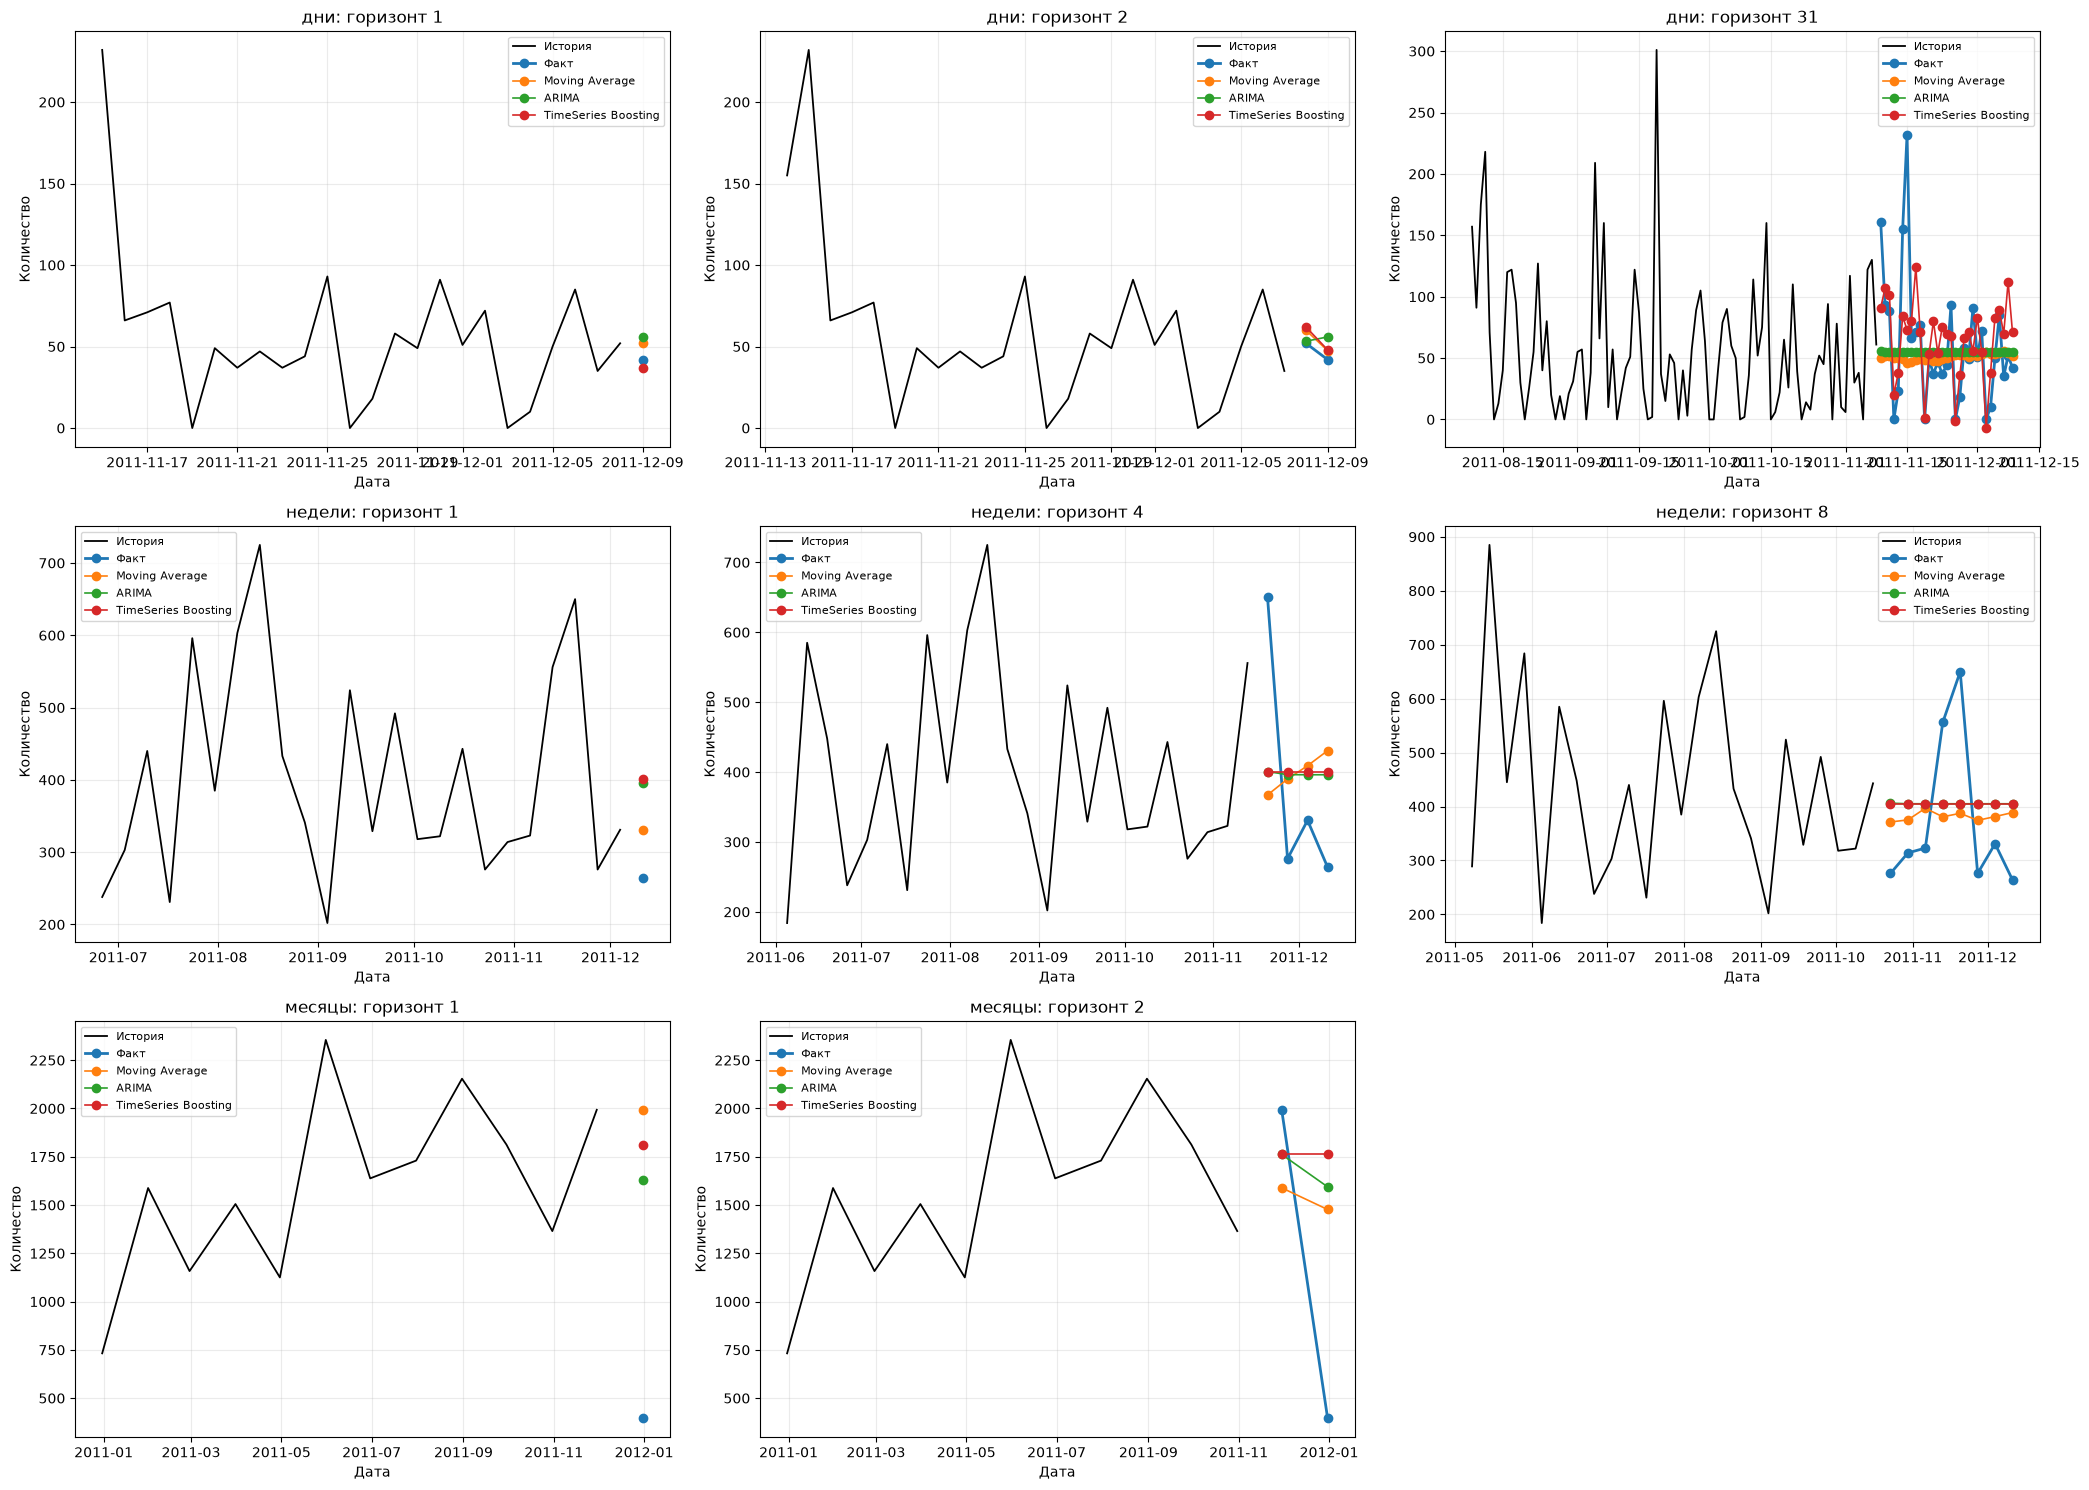

In [80]:
import matplotlib.pyplot as plt

aggregation_names = {"D": "дни", "W": "недели", "ME": "месяцы"}

fig, axes = plt.subplots(3, 3, figsize=(21, 15), sharey=False)

for row, aggregation in enumerate(["D", "W", "ME"]):
    horizons = horizons_by_frequency[aggregation]

    for column in range(3):
        ax = axes[row, column]

        if column >= len(horizons):
            ax.axis("off")
            continue

        horizon = horizons[column]
        latest = latest_forecasts[aggregation][horizon]
        train = latest["train"]
        test = latest["test"]

        history = train["Quantity"].tail(max(horizon * 3, 24))
        ax.plot(history.index, history.values, label="История", color="black", linewidth=1.3)
        ax.plot(test.index, test["Quantity"].values, label="Факт", marker="o", linewidth=2)

        for model_name, predicted in latest["predictions"].items():
            ax.plot(predicted.index, predicted.values, label=model_name, marker="o", linewidth=1.2)

        ax.set_title(f"{aggregation_names[aggregation]}: горизонт {horizon}")
        ax.set_xlabel("Дата")
        ax.set_ylabel("Количество")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


In [82]:
metric_for_selection = "MAE"

best_by_horizon = (
    results
    .groupby(["Aggregation", "Horizon", "Model"])[["MAE", "RMSE"]]
    .mean()
    .reset_index()
)

winner_rows = []
for (aggregation, horizon), group in best_by_horizon.groupby(["Aggregation", "Horizon"]):
    winner = group.loc[group[metric_for_selection].idxmin()].copy()
    winner_rows.append(winner)

winners = pd.DataFrame(winner_rows).sort_values(["Aggregation", "Horizon"])
print("Лучшие модели по среднему MAE для каждого горизонта:")
display(winners[["Aggregation", "Horizon", "Model", "MAE", "RMSE"]].round(3))

for aggregation, aggregation_winners in winners.groupby("Aggregation", sort=False):
    frequency_names = {"D": "дни", "W": "недели", "ME": "месяцы"}
    winner_names = aggregation_winners["Model"]
    counts = winner_names.value_counts()
    most_winning_model = counts.index[0]

    print(
        f"Частота '{frequency_names.get(aggregation, aggregation)}': "
        f"по MAE чаще всего лучший результат у модели '{most_winning_model}' "
        f"({counts.iloc[0]} из {len(aggregation_winners)} горизонта(ов))."
    )


Лучшие модели по среднему MAE для каждого горизонта:


,Aggregation,Horizon,Model,MAE,RMSE
2,D,1,TimeSeries Boosting,43.818,43.818
3,D,2,ARIMA,43.950,49.967
6,D,31,ARIMA,44.755,60.225
9,D,61,ARIMA,45.196,61.549
14,ME,1,TimeSeries Boosting,403.714,403.714
17,ME,2,TimeSeries Boosting,341.750,415.870
20,W,1,TimeSeries Boosting,122.815,122.815
23,W,4,TimeSeries Boosting,121.510,137.998
26,W,8,TimeSeries Boosting,119.481,139.505


Частота 'дни': по MAE чаще всего лучший результат у модели 'ARIMA' (3 из 4 горизонта(ов)).
Частота 'месяцы': по MAE чаще всего лучший результат у модели 'TimeSeries Boosting' (2 из 2 горизонта(ов)).
Частота 'недели': по MAE чаще всего лучший результат у модели 'TimeSeries Boosting' (3 из 3 горизонта(ов)).


# Шаг 6. Выводы

### 1. Какая модель лучше для каждого горизонта

Для выбора победителя в каждой комбинации «частота агрегации — горизонт» используется минимальное среднее значение **MAE** по expanding-window splits. Таблица с результатами выводится ячейкой непосредственно перед этим разделом.

Полученный рейтинг следует читать с учётом RMSE:

- MAE определяет наиболее типичную абсолютную ошибку в штуках товара.
- RMSE показывает чувствительность модели к редким большим промахам.

Победитель по MAE не обязательно остаётся лучшим по всем метрикам: если RMSE заметно ниже у другой модели, она может быть предпочтительнее при наличии дорогих выбросов. Итоговая модель для практического применения должна поэтому выбираться для конкретной частоты и горизонта, а не переноситься механически на весь ряд.

### 2. Как меняется качество при увеличении горизонта

Увеличение горизонта обычно повышает неопределённость прогнозирования. Чем дальше прогнозная точка от конца обучающей выборки, тем выше вероятность накопления ошибок и тем меньше влияния последних фактических наблюдений на крайние значения.

Это проявляется в таблицах в виде роста MAE и RMSE у многих моделей. Исключения возможны: длинный горизонт иногда выглядит стабильнее у одношаговой рекуррентной модели из-за сглаживания краткосрочных всплесков, а короткий горизонт может быть заметно хуже при случайных ежедневных колебаниях спроса.

При росте горизонта особенно растёт риск систематического смещения: бустинг и рекурсивные модели передают предыдущие ошибки в следующие шаги, а ARIMA начинает сильнее зависеть от оценки тренда и параметров автокорреляции.

### 3. Вероятные ошибки и ограничения моделей

- **Скользящее среднее** эффективно как простой baseline, но сглаживает тренд и резкие всплески. После структурного изменения спроса оно может медленно адаптироваться и давать смещённые прогнозы.
- **ARIMA** может учитывать зависимость от прошлых значений и ошибок, однако требует достаточно стабильного ряда. На малой выборке оценки параметров нестабильны, возможны предупреждения о сходимости, а рекурсивные и сезонные изменения могут быть не представлены параметрами модели.
- **Бустинг** использует лаговые и календарные признаки, поэтому способен выявлять нелинейные закономерности. Ограничения: мало данных для длинных лагов и редких режимов, риск переобучения, отсутствие явного гарантированного экстраполяционного поведения и распространение рекурсивной ошибки на последующие шаги.

Дополнительные ограничения датасета:

- Товарный ряд содержит нулевые и редкие продажи, поэтому абсолютные ошибки могут быть малы не только благодаря хорошей модели, но и из-за низкого базового объёма спроса.
- Данные могут содержать выбросы и праздничные всплески, которые искажают средние метрики и обучающие выборки.
- Месячная выборка особенно короткая, поэтому результаты для горизонта 1–2 месяца менее устойчивы, чем дневные или недельные.
- MAE и RMSE чувствительны к редким единицам с очень большим спросом.

**Практический итог:** по приведённой таблице следует выбирать модель отдельно для дня, недели и месяца и отдельно для каждого горизонта. Лучшие настройки должны обновляться по мере поступления новых наблюдений, а любой выбор нужно дополнительно проверять на свежем отложенном периоде. 
